In [66]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [67]:
plt.style.use("ggplot")

In [68]:

df = pd.read_csv(
    "ShortenDataSet.csv",)


In [69]:
df

,LABEL,TEXT
0,ham,Your opinion about me? 1. Over 2. Jada 3. Kusr...
1,ham,What's up? Do you want me to come online? If y...
2,ham,So u workin overtime nigpun?
3,ham,"Also sir, i sent you an email about how to log..."
4,Smishing,Please Stay At Home. To encourage the notion o...
...,...,...
5966,ham,:( but your not here....
5967,ham,Becoz its &lt;#&gt; jan whn al the post ofic...
5968,ham,Its a valentine game. . . send dis msg to all ...
5969,ham,We r outside already.


In [70]:
df.shape

(5971, 2)

In [71]:
df.dtypes

LABEL    str
TEXT     str
dtype: object

In [72]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5971 entries, 0 to 5970
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   LABEL   5971 non-null   str  
 1   TEXT    5971 non-null   str  
dtypes: str(2)
memory usage: 93.4 KB


In [73]:
df.isnull().sum().sum()

np.int64(0)

In [74]:
df.duplicated().sum() / df.shape[0] * 100

#precentage of how many are duplicated

np.float64(1.4737899849271479)

In [75]:
df.drop_duplicates(inplace=True)

In [76]:
df

,LABEL,TEXT
0,ham,Your opinion about me? 1. Over 2. Jada 3. Kusr...
1,ham,What's up? Do you want me to come online? If y...
2,ham,So u workin overtime nigpun?
3,ham,"Also sir, i sent you an email about how to log..."
4,Smishing,Please Stay At Home. To encourage the notion o...
...,...,...
5965,ham,I'm in class. Did you get my text.
5966,ham,:( but your not here....
5967,ham,Becoz its &lt;#&gt; jan whn al the post ofic...
5968,ham,Its a valentine game. . . send dis msg to all ...


In [77]:
df["LABEL"].value_counts()

LABEL
ham         4834
Smishing     551
spam         453
Spam          23
smishing      22
Name: count, dtype: int64

In [78]:
df["LABEL"].value_counts(normalize=True)*100

LABEL
ham         82.168961
Smishing     9.365970
spam         7.700153
Spam         0.390957
smishing     0.373959
Name: proportion, dtype: float64

<function matplotlib.pyplot.show(close=None, block=None)>

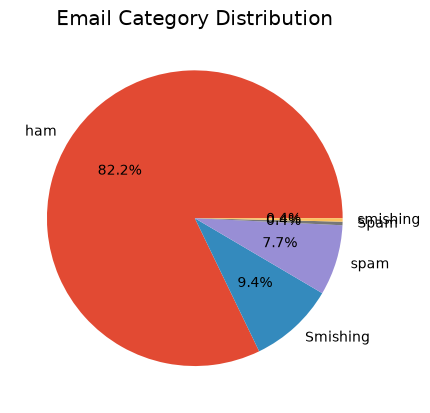

In [79]:

df["LABEL"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%"
)

plt.ylabel("")
plt.title("Email Category Distribution")
plt.show


In [80]:
df["LABEL"] = df["LABEL"].map({
    "ham" :0,
    "Smishing" : 1,
    "smishing" : 1,
    "spam" : 2,
    "Spam" : 2
    
})

In [81]:
df.head()

,LABEL,TEXT
0,0,Your opinion about me? 1. Over 2. Jada 3. Kusr...
1,0,What's up? Do you want me to come online? If y...
2,0,So u workin overtime nigpun?
3,0,"Also sir, i sent you an email about how to log..."
4,1,Please Stay At Home. To encourage the notion o...


In [82]:
import warnings
warnings.filterwarnings("ignore")

In [85]:
import sklearn
from sklearn.model_selection import train_test_split

In [86]:
X= df["TEXT"]

In [87]:
y= df["LABEL"]

In [89]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify= y
)

In [91]:
from sklearn.feature_extraction.text import TfidfVectorizer

tf = TfidfVectorizer(
    stop_words= "english",
    max_features= 5000,
    ngram_range= (1,2)
)

In [92]:
X_train_tf = tf.fit_transform(X_train)

In [94]:
X_test_tf = tf.transform(X_test)

In [97]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.model_selection import RandomizedSearchCV


In [98]:
models = {
    "Navie Bayes": (
        MultinomialNB(),
        {
            "alpha" : [0.1, 0.5, 1, 2, 5]
        }
    ), 
    "LogisticRegression" : (
        LogisticRegression(
            class_weight= "balanced",
            max_iter= 1000
        ),
        {
            "C" : [0.01, 0.1, 1, 10, 100]
        }
    ),
    "Linear SWM": (
        LinearSVC(
            class_weight="balanced"
        ),
        {
            "C" : [0.01, 0.1, 1, 10, 10]
        }
        
    ), 
    "Random Forest": (
        RandomForestClassifier(
            class_weight="balanced"
        ),
        {
            "n_estimators" : [100, 200, 300],
            "max_depth" : [10, 20, None],
            "min_samples_split" : [2, 5, 10]
        }
    ),
    "Decision Tree": (
        DecisionTreeClassifier(
            class_weight="balanced"
        ),
        {
         "max_depth" : [10, 20, None],
         "min_samples_split" : [2, 5, 10]
        }
    ),

    "Gradient Boosting" : (
        GradientBoostingClassifier(),
        {
             "n_estimators" : [100, 200],
             "learning_rate" : [0.01, 0.05, 0.1 ],
             "max_depth": [3,5]
        }
    ),
     "KNN": (
         KNeighborsClassifier(),
         {
            "n_neighbors": [3,5,7,9] 
         }
     )

}

In [104]:
result = [ ]

best_models = {}

for name, (model, params) in models.items():

    search = RandomizedSearchCV(
        estimator= model,
        param_distributions= params,
        n_iter= 10,
        cv = 5,
        scoring="f1_weighted",
        n_jobs= -1
    )

    search.fit(X_train_tf,y_train)

    best_model = search.best_estimator_

    best_models[name] = best_model

    predictions = best_model.predict(X_test_tf)

    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(y_test, predictions, average="weighted")
    recall = recall_score(y_test, predictions, average="weighted")
    f1 = f1_score(y_test, predictions, average="weighted")

    try:
        probabilities = best_model.predict_proba(X_test_tf)
        auc = roc_auc_score(
            y_test,
            probabilities,
            multi_class="ovr",
            average="weighted",
            labels=best_model.classes_
    )
    except (ValueError, AttributeError):
        auc = np.nan

    result.append({
        "Model" : name,
        "Accuracy" : accuracy,
        "Precision" : precision,
        "Recall" : recall,
        "F1 Score" : f1,
        "ROC AUC" : auc,
        "Best Params" : search.best_params_

    })
        
    

    


In [110]:
result_df= pd.DataFrame(result)

result_df = result_df.sort_values(
    by = ["F1 Score", "ROC AUC"],
    ascending= False
)

In [111]:
result_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,Best Params
1,LogisticRegression,0.953271,0.951320,0.953271,0.952047,0.980764,{'C': 10}
0,Navie Bayes,0.953271,0.951385,0.953271,0.951994,0.983636,{'alpha': 0.1}
2,Linear SWM,0.951572,0.948631,0.951572,0.949476,NaN,{'C': 1}
3,Random Forest,0.949873,0.948067,0.949873,0.948841,0.978391,"{'n_estimators': 300, 'min_samples_split': 5, ..."
5,Gradient Boosting,0.937978,0.932006,0.937978,0.933274,0.972473,"{'n_estimators': 200, 'max_depth': 5, 'learnin..."
4,Decision Tree,0.913339,0.917605,0.913339,0.915283,0.910281,"{'min_samples_split': 2, 'max_depth': None}"
6,KNN,0.893798,0.886091,0.893798,0.869632,0.851737,{'n_neighbors': 3}


In [113]:
result_df.style.background_gradient(
    cmap= "Greens",
    subset= ["Accuracy", "Precision", "Recall", "F1 Score", "ROC AUC"]
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,Best Params
1,LogisticRegression,0.953271,0.951320,0.953271,0.952047,0.980764,{'C': 10}
0,Navie Bayes,0.953271,0.951385,0.953271,0.951994,0.983636,{'alpha': 0.1}
2,Linear SWM,0.951572,0.948631,0.951572,0.949476,nan,{'C': 1}
3,Random Forest,0.949873,0.948067,0.949873,0.948841,0.978391,"{'n_estimators': 300, 'min_samples_split': 5, 'max_depth': None}"
5,Gradient Boosting,0.937978,0.932006,0.937978,0.933274,0.972473,"{'n_estimators': 200, 'max_depth': 5, 'learning_rate': 0.1}"
4,Decision Tree,0.913339,0.917605,0.913339,0.915283,0.910281,"{'min_samples_split': 2, 'max_depth': None}"
6,KNN,0.893798,0.886091,0.893798,0.869632,0.851737,{'n_neighbors': 3}


In [116]:
result_df.reset_index(inplace=True)

In [118]:
result_df.drop(columns= "index", inplace=True)

In [120]:
result_df

,level_0,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,Best Params
0,0,LogisticRegression,0.953271,0.951320,0.953271,0.952047,0.980764,{'C': 10}
1,1,Navie Bayes,0.953271,0.951385,0.953271,0.951994,0.983636,{'alpha': 0.1}
2,2,Linear SWM,0.951572,0.948631,0.951572,0.949476,NaN,{'C': 1}
3,3,Random Forest,0.949873,0.948067,0.949873,0.948841,0.978391,"{'n_estimators': 300, 'min_samples_split': 5, ..."
4,4,Gradient Boosting,0.937978,0.932006,0.937978,0.933274,0.972473,"{'n_estimators': 200, 'max_depth': 5, 'learnin..."
5,5,Decision Tree,0.913339,0.917605,0.913339,0.915283,0.910281,"{'min_samples_split': 2, 'max_depth': None}"
6,6,KNN,0.893798,0.886091,0.893798,0.869632,0.851737,{'n_neighbors': 3}


In [122]:
best_model_name = result_df.iloc[0]["Model"]

In [123]:
best_model_name

'LogisticRegression'

In [125]:
best_model = best_models[best_model_name]

In [127]:
best_model

,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",10
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to 

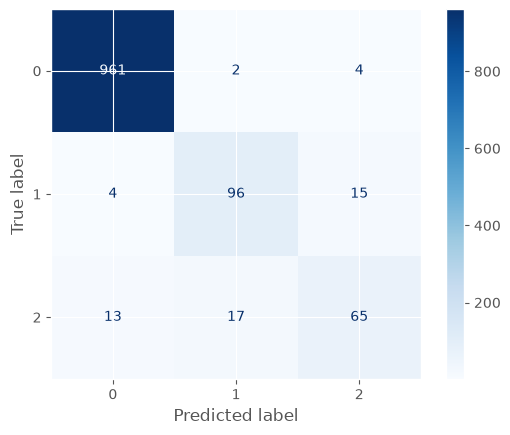

In [131]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_estimator(
 best_model,
 X_test_tf,
 y_test,
 cmap = "Blues"
)

In [161]:
texts = [
    "Hey are how you!",
    "Congratulations! You won a free iPhone. Click here now.",
    "Just a reminder, we have a meeting tomorrow",
    "URGENT! Claim your $1000 Walmart gift card today!"
   "Hello from Orange. For 1 month's free access to games, news and sport, plus 10 free texts and 20 photo messages, reply YES. Terms apply: www.orange.co.uk/ow"

]

texts_vectorized = tf.transform(texts)

predictionsTwo = best_model.predict(texts_vectorized)

for i in range(len(texts)):
    prediction = predictionsTwo[i]

    label = "They are phishing or scamming!" if prediction == 2 else \
            "They are phishing or scamming! (smishing)" if prediction == 1 else \
            "This is fine! (ham)"

    print(label, ":", texts[i])


This is fine! (ham) : Hey are how you!
They are phishing or scamming! (smishing) : Congratulations! You won a free iPhone. Click here now.
This is fine! (ham) : Just a reminder, we have a meeting tomorrow
They are phishing or scamming! (smishing) : URGENT! Claim your $1000 Walmart gift card today!Hello from Orange. For 1 month's free access to games, news and sport, plus 10 free texts and 20 photo messages, reply YES. Terms apply: www.orange.co.uk/ow


In [164]:
import pickle

with open("spam_detector_modelv1.pkl","wb" ) as file:
    pickle.dump(best_model, file)

In [165]:
with open ("tf_vectorizer.pkl", "wb") as file:
    pickle.dump(tf, file)

print("Woohoo! It's done!")

Woohoo! It's done!
